In [66]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.signal import find_peaks
from scipy.interpolate import interp1d
from scipy.stats import linregress
import matplotlib.pyplot as plt

In [95]:
long = np.genfromtxt('Substrato.txt',usecols =0, delimiter = '\t')
Trans_s = np.genfromtxt('Substrato.txt',usecols =1, delimiter = '\t')
Trans_f = np.genfromtxt('ThinFilm.txt',usecols =1, delimiter = '\t')
l = long*1e9

In [96]:
 

#Primero usando Plotly
fig = go.Figure()
fig.add_trace(go.Scatter(x = l, y = Trans_f, mode='lines', name='TiO2/Sustrato'))
fig.add_trace(go.Scatter(x = l, y = Trans_s, mode='lines', name='Sustrato'))
fig.update_yaxes(range=[0,1], title_text='Transmitancia (%)')
fig.update_xaxes(range=[200, 1000], title_text='Longitud de onda (nm)')
fig.update_layout(autosize=False, width=700, height=500)
fig.show()
 

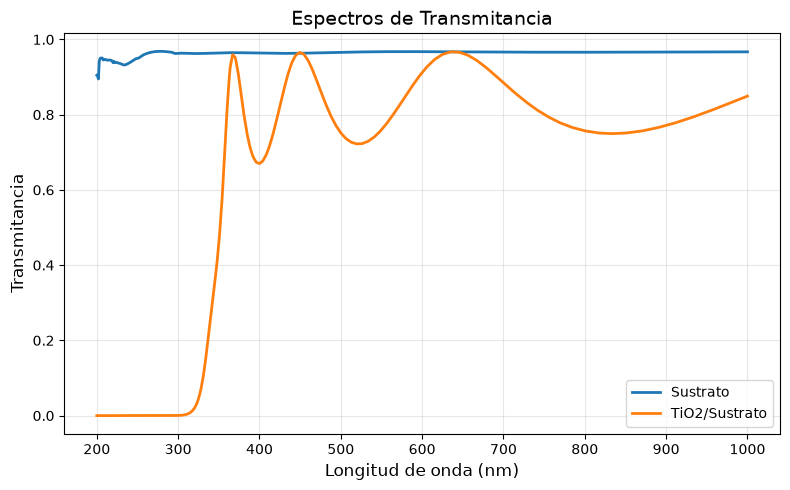

In [97]:
#Ahora usemo Matplotlib
plt.figure(figsize=(8, 5))
plt.plot(l, Trans_s, label='Sustrato', linewidth=2)
plt.plot(l, Trans_f, label='TiO2/Sustrato', linewidth=2)
plt.xlabel('Longitud de onda (nm)', fontsize=12)
plt.ylabel('Transmitancia', fontsize=12)
plt.title('Espectros de Transmitancia', fontsize=14)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



inicio = np.where(l==355)[0][0]
final = np.where(l==1000)[0][0]


In [98]:
T_film = Trans_f[inicio:final]
L = l[inicio:final]


In [99]:
maximos,_ = find_peaks(T_film,height=0)
minimos,_ = find_peaks(-T_film, height=-np.inf)

In [100]:
print('maximos en:')
for i in maximos:
    print(L[i],'nm')
    
print('minimos en:')
for i in minimos:
    print(L[i],'nm')

maximos en:
367.0 nm
450.0 nm
635.0 nm
minimos en:
400.0 nm
520.0 nm
833.0 nm


In [101]:


#se puede cambiar entre "linear" y "quadratic"
sup_env_func = interp1d(L[maximos], T_film[maximos], kind='quadratic', fill_value='extrapolate')
inf_env_func = interp1d(L[minimos], T_film[minimos], kind='quadratic', fill_value='extrapolate')



In [102]:
sup_env = sup_env_func(L)
inf_env = inf_env_func(L)

In [103]:
#Primero con Plotly
fig = go.Figure()
fig.add_trace(go.Scatter(x = l, y = Trans_f, mode='lines', name='TiO2/Sustrato'))
fig.add_trace(go.Scatter(x = L, y = sup_env, mode='lines', name='Envolvente superior'))
fig.add_trace(go.Scatter(x = L, y = inf_env, mode='lines', name='Envolvente inferior'))
fig.update_yaxes(range=[0,1], title_text='Transmitancia')
fig.update_xaxes(range=[200, 1000], title_text='Longitud de onda (nm)')
fig.update_layout(autosize=False, width=900, height=500)
fig.show()

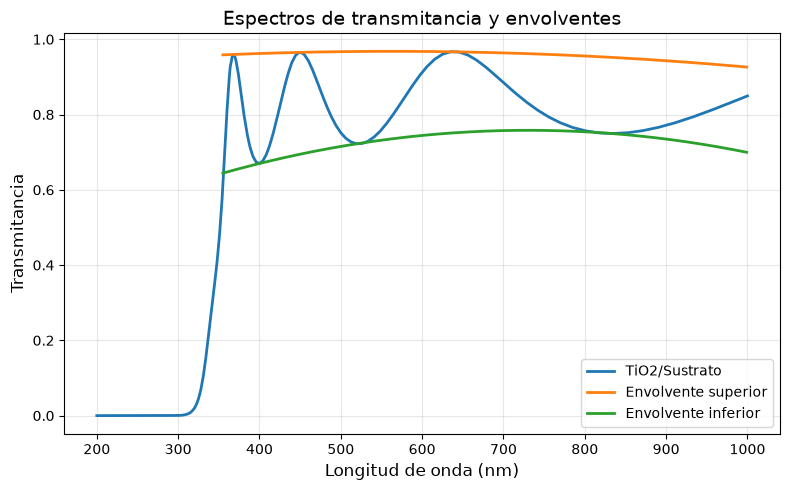

In [76]:
#Ahora usemos Matplotlib
plt.figure(figsize=(8, 5))
plt.plot(l, Trans_f, label='TiO2/Sustrato', linewidth=2)
plt.plot(L, sup_env, label='Envolvente superior', linewidth=2)
plt.plot(L, inf_env, label='Envolvente inferior', linewidth=2)
plt.xlabel('Longitud de onda (nm)', fontsize=12)
plt.ylabel('Transmitancia', fontsize=12)
plt.title('Espectros de transmitancia y envolventes', fontsize=14)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



In [104]:
Trans_s = 0.966 #Se toma constante
TM_env = sup_env/1
Tm_env = inf_env/1

In [109]:
s = 1 / Trans_s + ((1 / Trans_s ** 2) - 1) ** (1/2)
N = 2 * s * ((TM_env - Tm_env)/(TM_env * Tm_env)) + ((s ** 2 + 1) / 2)
n = (N + (N ** 2 - s ** 2) ** (1/2)) ** (1/2)
print(s)
print(N)


1.3028385778568707
[2.67434769 2.67080749 2.66728322 2.66377481 2.66028219 2.65680528
 2.653344   2.64989829 2.64646807 2.64305327 2.63965381 2.63626962
 2.63290063 2.62954678 2.62620798 2.62288418 2.61957529 2.61628126
 2.61300202 2.60973749 2.60648761 2.60325231 2.60003153 2.59682519
 2.59363325 2.59045562 2.58729224 2.58414306 2.581008   2.57788701
 2.57478001 2.57168696 2.56860778 2.56554242 2.56249081 2.55945289
 2.55642861 2.5534179  2.5504207  2.54743696 2.54446661 2.5415096
 2.53856587 2.53563536 2.53271802 2.52981378 2.5269226  2.52404442
 2.52117917 2.51832681 2.51548729 2.51266054 2.50984651 2.50704515
 2.50425641 2.50148022 2.49871655 2.49596534 2.49322654 2.49050009
 2.48778594 2.48508405 2.48239435 2.47971681 2.47705138 2.47439799
 2.47175661 2.46912719 2.46650967 2.46390401 2.46131016 2.45872808
 2.45615771 2.45359901 2.45105193 2.44851643 2.44599246 2.44347997
 2.44097893 2.43848928 2.43601098 2.43354399 2.43108825 2.42864374
 2.4262104  2.42378819 2.42137707 2.418977  

In [108]:
print(n)

[2.23827785 2.23658063 2.2348894  2.23320413 2.23152482 2.22985143
 2.22818395 2.22652236 2.22486665 2.22321678 2.22157275 2.21993453
 2.2183021  2.21667546 2.21505457 2.21343942 2.21182999 2.21022627
 2.20862824 2.20703587 2.20544916 2.20386808 2.20229262 2.20072275
 2.19915847 2.19759975 2.19604658 2.19449894 2.19295682 2.19142019
 2.18988905 2.18836337 2.18684314 2.18532834 2.18381896 2.18231498
 2.18081639 2.17932316 2.17783529 2.17635276 2.17487555 2.17340365
 2.17193705 2.17047572 2.16901965 2.16756883 2.16612324 2.16468288
 2.16324771 2.16181774 2.16039294 2.15897331 2.15755882 2.15614946
 2.15474522 2.15334609 2.15195205 2.15056308 2.14917918 2.14780033
 2.14642652 2.14505773 2.14369396 2.14233518 2.14098138 2.13963256
 2.1382887  2.13694978 2.13561579 2.13428673 2.13296257 2.13164331
 2.13032894 2.12901944 2.12771479 2.12641499 2.12512003 2.12382989
 2.12254457 2.12126404 2.1199883  2.11871734 2.11745114 2.1161897
 2.114933   2.11368103 2.11243378 2.11119124 2.1099534  2.10872

In [79]:
fig = go.Figure()
fig.add_trace(go.Scatter(x = L, y = n, mode='lines', name='n de TiO2'))
fig.update_yaxes(range=[0,3], title_text='Índice de refracción')
fig.update_xaxes(range=[300, 1000], title_text='Longitud de onda (nm)')
fig.update_layout(autosize=False, width=900, height=500)
fig.show()

In [80]:
l1_max = L[maximos[1]]
l2_max = L[maximos[2]]
n1_max = n[maximos[1]]
n2_max = n[maximos[2]]
d_max = (l1_max*l2_max) / (2 * (l2_max*n1_max - l1_max*n2_max))
print('Espesor de:')
print(round(d_max, 2), 'nm')
l1_min = L[minimos[1]]
l2_min = L[minimos[2]]
n1_min = n[minimos[1]]
n2_min = n[minimos[2]]
d_min = (l1_min*l2_min) / (2 * (l2_min*n1_min - l1_min*n2_min))
print('Espesor de:')
print(round(d_min, 2), 'nm')

Espesor de:
312.66 nm
Espesor de:
315.46 nm


Método de Tauc Plot

In [81]:
T = Trans_f/1 #Aquí deben revisar si está en porcentaje o fracción
A = - np.log(T)

In [82]:
fig = go.Figure()
fig.add_trace(go.Scatter(x = l, y = A, mode='lines', name='Película TiO2'))
fig.update_yaxes(range=[0,15], title_text='Absorbancia')
fig.update_xaxes(range=[200, 1000], title_text='Longitud de onda (nm)')
fig.update_layout(autosize=False, width=900, height=500)
fig.show()

In [83]:
d_cm = d_max * 1e-7 #Se pasa a centímetros
alph = 2.303 * A / d_cm
hv = 1239.8 / l

In [84]:
ahv_2 = (alph * hv) ** 2 #Directa
ahv_1_2 = (alph * hv) ** (1/2) #Indirecta

In [85]:
#Primero usamos Plotly

# Se crea figura con dos columnas
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=["Transición directa", "Transición indirecta"]
)

# Subplot 1 — Transición directa
fig.add_trace(
    go.Scatter(x=hv, y=ahv_2, mode='lines', name=r'$(\alpha h\nu)^2$'),
    row=1, col=1
)
fig.update_xaxes(title_text='hv (eV)', range=[1,7], row=1, col=1)
fig.update_yaxes(title_text=r'$(\alpha h \nu)^2$', row=1, col=1)

# Subplot 2 — Transición indirecta
fig.add_trace(
    go.Scatter(x=hv, y=ahv_1_2, mode='lines', name=r'$(\alpha h\nu)^{1/2}$'),
    row=1, col=2
)

fig.update_xaxes(title_text='hv (eV)', range=[1,7], row=1, col=2)
fig.update_yaxes(title_text=r'$(\alpha h \nu)^{1/2}$', row=1, col=2)

# Layout
fig.update_layout(
    autosize=False,
    width=900,
    height=400,
    showlegend=False
)

fig.show()

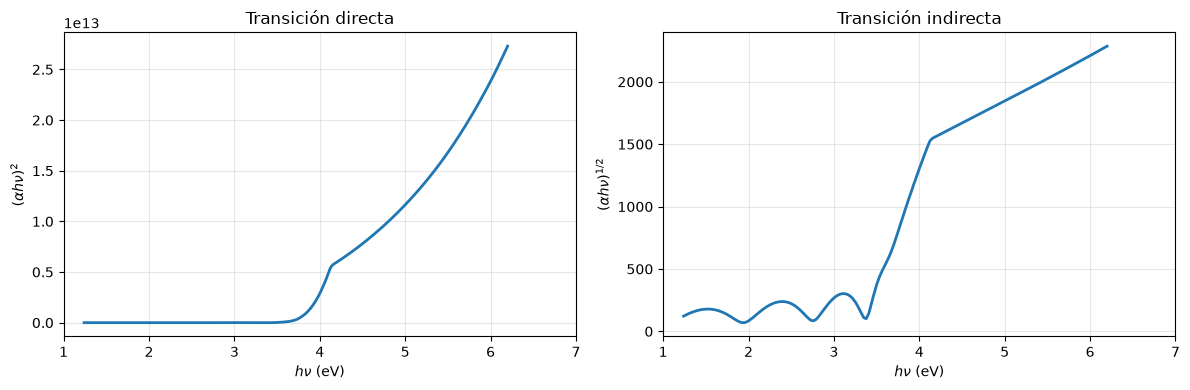

In [86]:
#Ahora usamos Matplotlib

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Subplot 1 — Transición directa
axes[0].plot(hv, ahv_2, linewidth=2)
axes[0].set_title("Transición directa", fontsize=12)
axes[0].set_xlabel(r'$h \nu$ (eV)')
axes[0].set_ylabel(r'$(\alpha h \nu)^2$')
axes[0].set_xlim(1, 7)
axes[0].grid(alpha=0.3)

# Subplot 2 — Transición indirecta
axes[1].plot(hv, ahv_1_2, linewidth=2)
axes[1].set_title("Transición indirecta", fontsize=12)
axes[1].set_xlabel(r'$h \nu$ (eV)')
axes[1].set_ylabel(r'$(\alpha h \nu)^{1/2}$')
axes[1].set_xlim(1, 7)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [87]:
def intervalo(x, xmin, xmax):
    idx = np.where((x > xmin) & (x < xmax))[0]
    return idx

In [88]:
# Selección de intervalos
mask_dir = intervalo(hv, 3.95, 4.05) # Transición directa
mask_ind = intervalo(hv, 3.58, 4.11) # Transición indirecta

# Datos dentro de esa región

x_dir = hv[mask_dir]
y_dir = ahv_2[mask_dir] # (αhv)^2 para transición directa

x_ind = hv[mask_ind]  
y_ind = ahv_1_2[mask_ind] # (αhv)^(1/2) para transición indirecta

In [89]:
# Usamos scipy.stats.linregress para obtener la pendiente (slope)
# y la ordenada al origen (intercept) de la recta que mejor ajusta
# los datos seleccionados en la región lineal del Tauc plot.


# linregress devuelve: slope, intercept, r_value, p_value, std_err
slope_dir, intercept_dir, *_ = linregress(x_dir, y_dir)
slope_ind, intercept_ind, *_ = linregress(x_ind, y_ind)


# Cálculo del band gap (Eg) por extrapolación

# La recta del ajuste es: y = slope * x + intercept.
# El band gap Eg se obtiene al resolver y = 0 --> x = -intercept / slope.
# Añadimos una comprobación para evitar división por cero si slope≈0.

if abs(slope_dir) < 1e-12:
    raise RuntimeError("Pendiente (slope_dir) demasiado cercana a cero; revisar la selección de la región lineal.")
Eg_dir = -intercept_dir / slope_dir

if abs(slope_ind) < 1e-12:
    raise RuntimeError("Pendiente (slope_ind) demasiado cercana a cero; revisar la selección de la región lineal.")
Eg_ind = -intercept_ind / slope_ind

# Impresión de resultados (con 2 decimales)
print(f"Eg (directo): {Eg_dir:.2f} eV")
print(f"Eg (indirecto): {Eg_ind:.2f} eV")

Eg (directo): 3.83 eV
Eg (indirecto): 3.34 eV


In [90]:
# Definimos un rango extendido de x:
#  - Inicia un poco antes que el mínimo valor de x seleccionado
#  - Termina justo después del Eg obtenido para ver claramente el cruce

# Para el caso directo
x_min_dir = min(x_dir) - 0.3
x_max_dir = Eg_dir + 0.5
x_fit_dir = np.linspace(x_min_dir, x_max_dir, 200)

# Recta ajustada (directo)
y_fit_dir = slope_dir * x_fit_dir + intercept_dir

# Para el caso indirecto
x_min_ind = min(x_ind) - 0.3
x_max_ind = Eg_ind + 0.5
x_fit_ind = np.linspace(x_min_ind, x_max_ind, 200)

# Recta ajustada (indirecto)
y_fit_ind = slope_ind * x_fit_ind + intercept_ind

In [91]:
# Primero usamos Plotly
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=["Transición directa", "Transición indirecta"]
)

# 1) Transición directa (subplot 1)
fig.add_trace(
    go.Scatter(
        x=hv, y=ahv_2, 
        mode='lines', 
        name='Datos directos',
        line=dict(color='blue')
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=x_fit_dir, y=y_fit_dir,
        mode='lines',
        name='Ajuste lineal directo',
        line=dict(color='red', dash='dash')
    ),
    row=1, col=1
)

# Línea vertical marcando Eg
fig.add_trace(
    go.Scatter(
        x=[Eg_dir, Eg_dir],
        y=[0, max(y_fit_dir)],
        mode='lines',
        line=dict(color='gray', dash='dot'),
        name=f'Eg directo = {Eg_dir:.2f} eV'
    ),
    row=1, col=1
)

fig.update_xaxes(title_text='hv (eV)', range=[1, 7], row=1, col=1)
fig.update_yaxes(title_text=r'$(\alpha h\nu)^2$', row=1, col=1)

# 2) Transición indirecta (subplot 2)
fig.add_trace(
    go.Scatter(
        x=hv, y=ahv_1_2,
        mode='lines',
        name='Datos indirectos',
        line=dict(color='blue')
    ),
    row=1, col=2
)

fig.add_trace(
    go.Scatter(
        x=x_fit_ind, y=y_fit_ind,
        mode='lines',
        name='Ajuste lineal indirecto',
        line=dict(color='red', dash='dash')
    ),
    row=1, col=2
)

# Línea vertical marcando Eg
fig.add_trace(
    go.Scatter(
        x=[Eg_ind, Eg_ind],
        y=[0, max(y_fit_ind)],
        mode='lines',
        line=dict(color='gray', dash='dot'),
        name=f'Eg indirecto = {Eg_ind:.2f} eV'
    ),
    row=1, col=2
)
fig.update_xaxes(title_text='hv (eV)', range=[1, 7], row=1, col=2)
fig.update_yaxes(title_text=r'$(\alpha h\nu)^{1/2}$', row=1, col=2)


# Ajustes generales
fig.update_layout(
    width=1000,
    height=420,
    showlegend=True
)

fig.show()

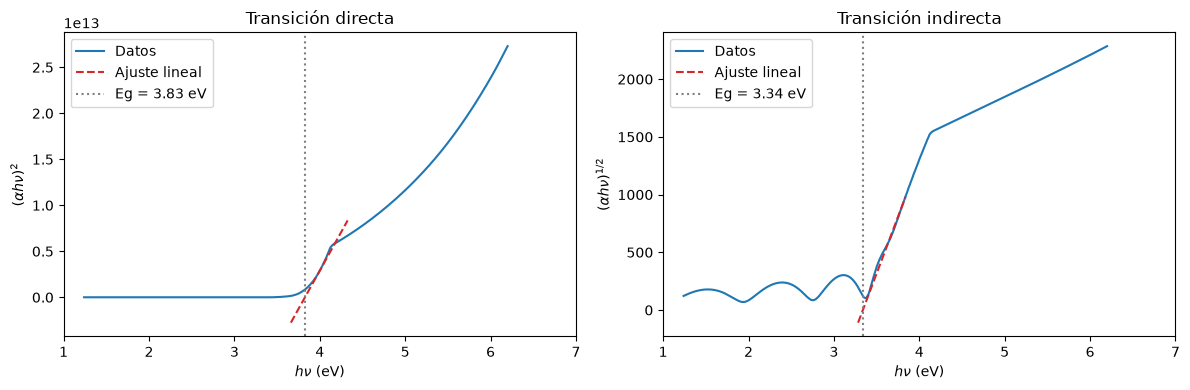

In [92]:
# Usando Matplotlib
# Gráficas: Tauc plot directo e indirecto
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Transición directa
axes[0].plot(hv, ahv_2, label='Datos', color='tab:blue')
axes[0].plot(x_fit_dir, y_fit_dir, '--', label='Ajuste lineal', color='tab:red')
# Línea vertical para indicar Eg
axes[0].axvline(Eg_dir, color='gray', linestyle=':', label=f'Eg = {Eg_dir:.2f} eV')
axes[0].set_xlabel(r'$h\nu$ (eV)')
axes[0].set_ylabel(r'$(\alpha h\nu)^2$')
axes[0].set_title('Transición directa')
axes[0].set_xlim(1, 7)
axes[0].legend()

# Transición indirecta
axes[1].plot(hv, ahv_1_2, label='Datos', color='tab:blue')
axes[1].plot(x_fit_ind, y_fit_ind, '--', label='Ajuste lineal', color='tab:red')
# Línea vertical para Eg
axes[1].axvline(Eg_ind, color='gray', linestyle=':', label=f'Eg = {Eg_ind:.2f} eV')
axes[1].set_xlabel(r'$h\nu$ (eV)')
axes[1].set_ylabel(r'$(\alpha h\nu)^{1/2}$')
axes[1].set_title('Transición indirecta')
axes[1].set_xlim(1, 7)
axes[1].legend()

plt.tight_layout()
plt.show()



Ejercicio 2

In [121]:
long = np.genfromtxt('Datos-S(1).txt',usecols =0, delimiter = '\t')
Trans_s = np.genfromtxt('Datos-S(1).txt',usecols =1, delimiter = '\t')
Trans_f = np.genfromtxt('Datos-1-1(1).txt',usecols =1, delimiter = '\t')
l = long
fig = go.Figure()
fig.add_trace(go.Scatter(x = l, y = Trans_f, mode='lines', name='TiO2/Sustrato'))
fig.add_trace(go.Scatter(x = l, y = Trans_s, mode='lines', name='Sustrato'))
fig.update_yaxes(range=[0,1], title_text='Transmitancia (%)')
fig.update_xaxes(range=[200, 1000], title_text='Longitud de onda (nm)')
fig.update_layout(autosize=False, width=700, height=500)
fig.show()
T_film = Trans_f[inicio:final]
L = l[inicio:final]
maximos,_ = find_peaks(T_film,height=0)
minimos,_ = find_peaks(-T_film, height=-np.inf)
print('maximos en:')
for i in maximos:
    print(L[i],'nm')
    
print('minimos en:')
for i in minimos:
    print(L[i],'nm')
sup_env_func = interp1d(L[maximos], T_film[maximos], kind='quadratic', fill_value='extrapolate')
inf_env_func = interp1d(L[minimos], T_film[minimos], kind='quadratic', fill_value='extrapolate')
sup_env = sup_env_func(L)
inf_env = inf_env_func(L)
fig = go.Figure()
fig.add_trace(go.Scatter(x = l, y = Trans_f, mode='lines', name='TiO2/Sustrato'))
fig.add_trace(go.Scatter(x = L, y = sup_env, mode='lines', name='Envolvente superior'))
fig.add_trace(go.Scatter(x = L, y = inf_env, mode='lines', name='Envolvente inferior'))
fig.update_yaxes(range=[0,1], title_text='Transmitancia')
fig.update_xaxes(range=[200, 1000], title_text='Longitud de onda (nm)')
fig.update_layout(autosize=False, width=900, height=500)
fig.show()
T_s = 0.966 #Se toma constante cuarzo
TM_env = sup_env/1
Tm_env = inf_env/1
s = 1 / T_s + ((1 / T_s ** 2) - 1) ** (1/2)
N = 2 * s * ((TM_env - Tm_env)/(TM_env * Tm_env)) + ((s ** 2 + 1) / 2)
n = (N + (N ** 2 - s ** 2) ** (1/2)) ** (1/2)
fig = go.Figure()
fig.add_trace(go.Scatter(x = L, y = n, mode='lines', name='n de TiO2'))
fig.update_yaxes(range=[0,3], title_text='Índice de refracción')
fig.update_xaxes(range=[300, 1000], title_text='Longitud de onda (nm)')
fig.update_layout(autosize=False, width=900, height=500)
fig.show()
l1_max = L[maximos[1]]
l2_max = L[maximos[2]]
n1_max = n[maximos[1]]
n2_max = n[maximos[2]]
d_max = (l1_max*l2_max) / (2 * (l2_max*n1_max - l1_max*n2_max))
print('Espesor de:')
print(round(d_max, 2), 'nm')
l1_min = L[minimos[1]]
l2_min = L[minimos[2]]
n1_min = n[minimos[1]]
n2_min = n[minimos[2]]
d_min = (l1_min*l2_min) / (2 * (l2_min*n1_min - l1_min*n2_min))
print('Espesor de:')
print(round(d_min, 2), 'nm')


maximos en:
444.0 nm
534.0 nm
702.0 nm
minimos en:
471.0 nm
597.0 nm
833.0 nm


C:\Users\hugoc\AppData\Local\Temp\ipykernel_10276\1074745260.py:40: RuntimeWarning: invalid value encountered in sqrt
  n = (N + (N ** 2 - s ** 2) ** (1/2)) ** (1/2)


Espesor de:
474.67 nm
Espesor de:
279.4 nm
